In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [20]:
# 1. Load the Weather Dataset
url = 'https://raw.githubusercontent.com/vega/vega/main/docs/data/seattle-weather.csv'
df = pd.read_csv(url)

print('Dataset loaded successfully!')
df.head()

Dataset loaded successfully!


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [21]:
print('Initial Missing Values:\n', df.isnull().sum())
print(f'Duplicate rows found: {df.duplicated().sum()}')
df.drop_duplicates(inplace=True)

Initial Missing Values:
 date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64
Duplicate rows found: 0


In [22]:
# B. Feature Engineering: Extract temporal features and calculate Avg Temp
df['date'] = pd.to_datetime(df['date'])
df['Month'] = df['date'].dt.month
df['Year'] = df['date'].dt.year
df['Avg_Temp'] = (df['temp_max'] + df['temp_min']) / 2

In [23]:
# Select features and target
X = df[['precipitation', 'temp_max', 'temp_min', 'wind', 'Avg_Temp', 'Month']]
y = df['weather']

In [24]:
#C. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
# E. Feature Scaling (Crucial for SVM distance metrics)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Features scaled using StandardScaler for SVM.')

Features scaled using StandardScaler for SVM.


In [26]:
# A. Logistic Regression Classifier - uses scaled data
log_reg = LogisticRegression(max_iter=500, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
acc_lr = accuracy_score(y_test, y_pred_lr)

In [27]:
print('--- Logistic Regression Results ---')
print(f'Accuracy: {acc_lr * 100:.2f}%')
print(classification_report(y_test, y_pred_lr, zero_division=0))

--- Logistic Regression Results ---
Accuracy: 78.50%
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         9
         fog       0.00      0.00      0.00        25
        rain       0.87      0.87      0.87       120
        snow       1.00      0.12      0.22         8
         sun       0.72      0.95      0.82       131

    accuracy                           0.78       293
   macro avg       0.52      0.39      0.38       293
weighted avg       0.71      0.78      0.73       293



In [28]:
# B. Decision Tree Classifier - uses unscaled (but imputed) data
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

In [29]:

print(classification_report(y_test, y_pred_dt, zero_division=0))

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         9
         fog       0.00      0.00      0.00        25
        rain       0.96      0.93      0.94       120
        snow       0.75      0.38      0.50         8
         sun       0.76      1.00      0.86       131

    accuracy                           0.84       293
   macro avg       0.49      0.46      0.46       293
weighted avg       0.75      0.84      0.78       293



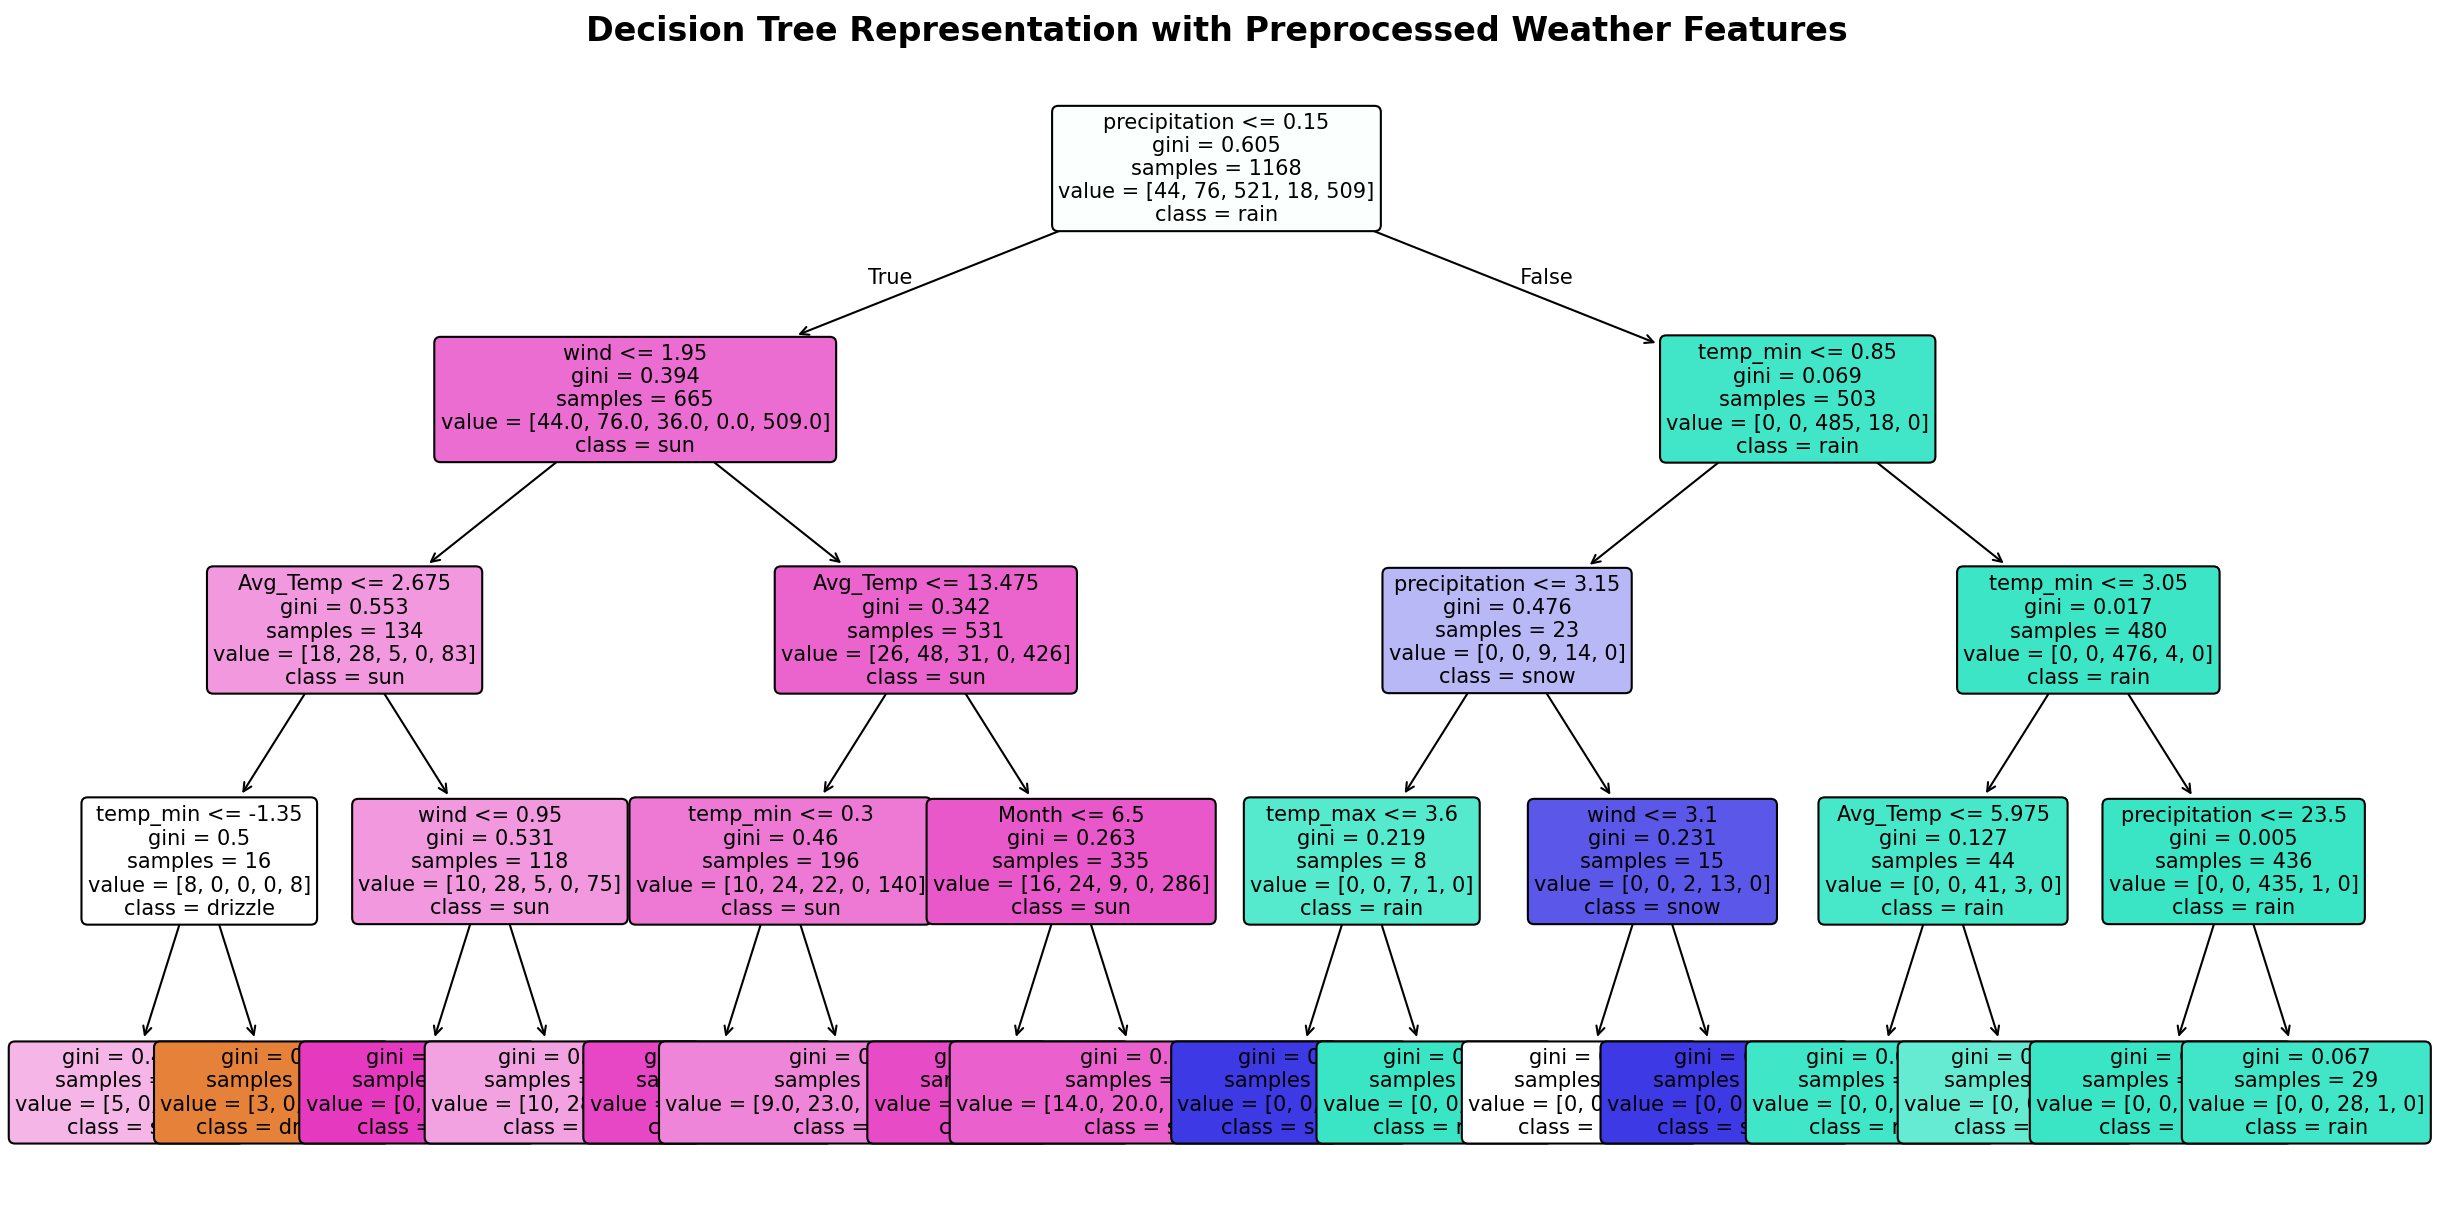

In [30]:
plt.figure(figsize=(20, 10), dpi=150)
plot_tree(
    dt_model,
    feature_names=list(X.columns),
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title(
    'Decision Tree Representation with Preprocessed Weather Features',
    fontsize=16,
    fontweight='bold',
)
plt.show()

In [31]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [32]:
y_pred = dt_model.predict(X_test)

In [33]:
# 1. Calculate Core Metrics
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

In [34]:
print('--- Model Evaluation Summary ---')
print(f'Accuracy:  {acc * 100:.2f}%')
print(f'Precision: {precision * 100:.2f}%')
print(f'Recall:    {recall * 100:.2f}%')
print(f'F1-Score:  {f1 * 100:.2f}% \n')

--- Model Evaluation Summary ---
Accuracy:  83.62%
Precision: 75.09%
Recall:    83.62%
F1-Score:  78.42% 



In [35]:
# Detailed Classification Report per Weather Class
print('--- Detailed Classification Report ---')
print(classification_report(y_test, y_pred, zero_division=0))

--- Detailed Classification Report ---
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         9
         fog       0.00      0.00      0.00        25
        rain       0.96      0.93      0.94       120
        snow       0.75      0.38      0.50         8
         sun       0.76      1.00      0.86       131

    accuracy                           0.84       293
   macro avg       0.49      0.46      0.46       293
weighted avg       0.75      0.84      0.78       293



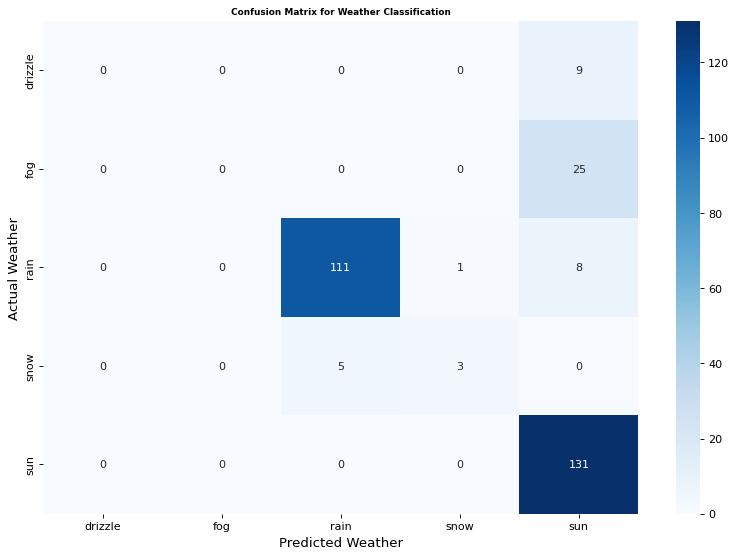

In [36]:
# 2. Generate and Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=dt_model.classes_)

plt.figure(figsize=(12, 8), dpi=80)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_,
)
plt.title(
    'Confusion Matrix for Weather Classification', fontsize=8, fontweight='bold'
)
plt.xlabel('Predicted Weather', fontsize=12)
plt.ylabel('Actual Weather', fontsize=12)
plt.show()